In [8]:
import torch
from torch import nn
import torchvision
import torchvision.transforms as T
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from torchvision.utils import save_image
device = 'cuda' if torch.cuda.is_available() else 'cpu'

In [9]:
transform = T.Compose([T.Resize(256),
                       T.ToTensor(),
                      ])
data = torchvision.datasets.ImageFolder(
    root = "Images",
    transform = transform)
batch_size = 16
dataloader = torch.utils.data.DataLoader(data, batch_size = batch_size, shuffle = True)

In [10]:
latent_dims = 100
class Encoder(nn.Module):
    def __init__(self, latent_dims):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 8, 3, stride = 2, padding = 1)
        self.conv2 = nn.Conv2d(8, 16, 3, stride = 2, padding = 1)
        self.batch2 = nn.BatchNorm2d(16)
        self.conv3 = nn.Conv2d(16, 32, 3, stride = 2, padding = 0)
        self.linear1 = nn.Linear(31 * 31* 32, 1024)
        self.linear2 = nn.Linear(1024, latent_dims)
        self.linear3 = nn.Linear(1024, latent_dims)
        self.N = torch.distributions.Normal(0, 1)
        self.N.loc = self.N.loc.cuda()
        self.N.scale = self.N.scale.cuda()

    def forward(self, x):    #返回（mu， std），这是数据服从的正态分布， z是潜向量组
        x = x.to(device)
        x = F.relu(self.conv1(x))
        x = F.relu(self.batch2(self.conv2(x)))
        x = F.relu(self.conv3(x))
        x = torch.flatten(x, start_dim = 1)
        x = F.relu(self.linear1(x))
        mu = self.linear2(x)    #这里的mu形状是(N, latent_dims)
        std = torch.exp(self.linear3(x))
        z = mu + std * self.N.sample(mu.shape)
        return mu, std, z

In [11]:
class Decoder(nn.Module):
    def __init__(self, latent_dims = 100):
        super().__init__()
        self.decoder_lin = nn.Sequential(nn.Linear(latent_dims, 1024),
                                         nn.ReLU(True),
                                         nn.Linear(1024, 31 * 31 * 32),
                                         nn.ReLU(True))
        self.unflatten = nn.Unflatten(dim = 1, unflattened_size = (32, 31, 31))
        self.decoder_conv = nn.Sequential(nn.ConvTranspose2d(32, 16, 3, stride = 2, output_padding = 1),
                                          nn.BatchNorm2d(16),
                                          nn.ReLU(True),
                                          nn.ConvTranspose2d(16, 8, 3, stride = 2, padding = 1, output_padding = 1),
                                          nn.BatchNorm2d(8),
                                          nn.ReLU(True),
                                          nn.ConvTranspose2d(8, 3, 3, stride = 2, padding = 1, output_padding = 1))

    def forward(self, x):
        x = self.decoder_lin(x)
        x = self.unflatten(x)
        x = self.decoder_conv(x)
        x = torch.sigmoid(x)
        return x

In [12]:
class VAE(nn.Module):
    def __init__(self, latent_dims = 100):
        super().__init__()
        self.encoder = Encoder(latent_dims)
        self.decoder = Decoder(latent_dims)

    def forward(self, x):
        x = x.to(device)
        mu, std, z = self.encoder(x)
        return mu, std, self.decoder(z)

In [13]:
def train_epoch(epoch):
    vae.train()
    epoch_loss = 0.0
    for imgs, _ in dataloader:
        imgs = imgs.to(device)
        mu, std, out = vae(imgs)
        reconstructed_loss = ((imgs - out) ** 2).sum()
        kl = ((std ** 2) / 2 + (mu ** 2) / 2 - torch.log(std) - 0.5).sum()
        loss = reconstructed_loss + kl
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()
    print(f'at epoch {epoch + 1}, loss is {epoch_loss}')

In [14]:
def plot_epoch():
    with torch.no_grad():
        noise = torch.randn(18, latent_dims).to(device)
        imgs = vae.decoder(noise).cpu()
        imgs = torchvision.utils.make_grid(imgs, 6, 3).numpy()
        fig, ax = plt.subplots(figsize = (6, 3), dpi = 100)
        plt.imshow(np.transpose(imgs, (1, 2, 0)))
        ax.axis('off')
        plt.show()

at epoch 1, loss is 45772296.734375


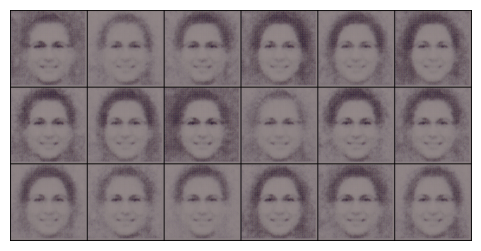

at epoch 2, loss is 28910924.66015625


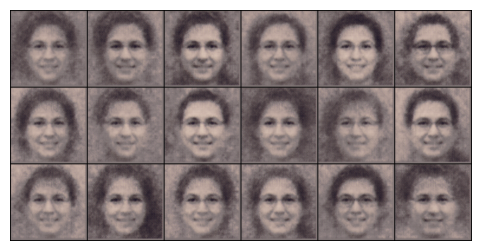

at epoch 3, loss is 19774144.71875


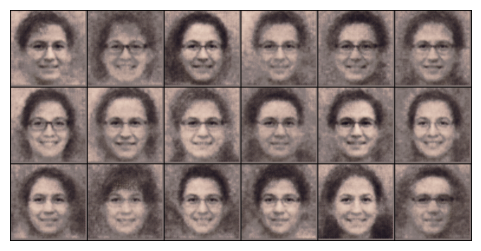

at epoch 4, loss is 16069516.21484375


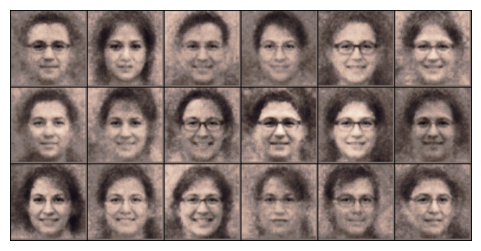

at epoch 5, loss is 13963556.7109375


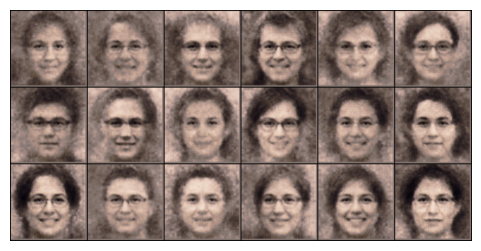

at epoch 6, loss is 12485493.04296875


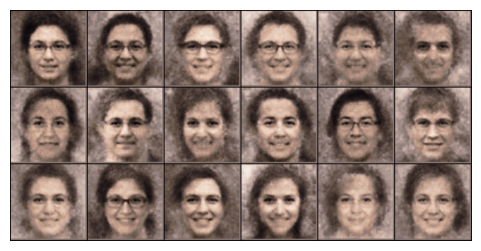

at epoch 7, loss is 11272012.4921875


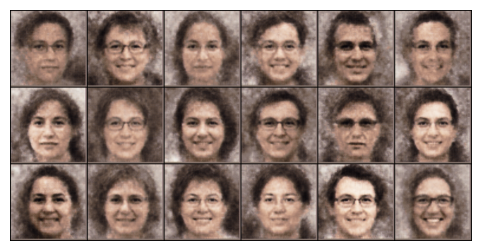

at epoch 8, loss is 10364190.966796875


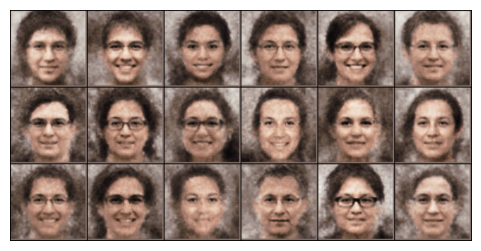

at epoch 9, loss is 9672124.280273438


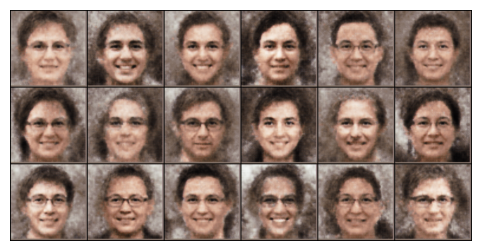

at epoch 10, loss is 9130406.946289062


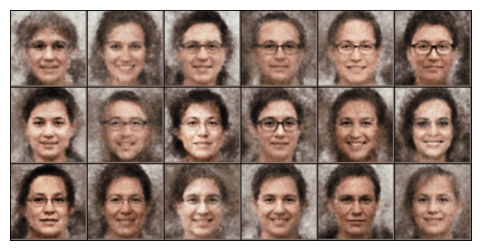

at epoch 11, loss is 8750726.319335938


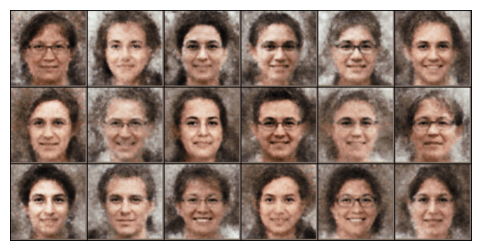

at epoch 12, loss is 8391771.530273438


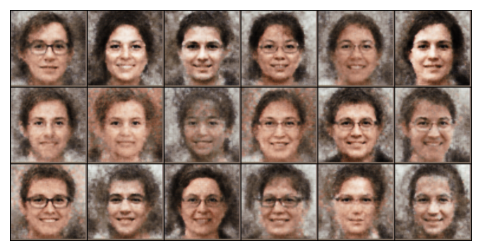

at epoch 13, loss is 8131303.458984375


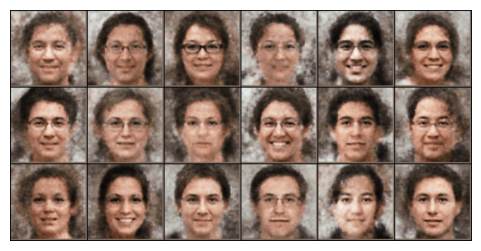

at epoch 14, loss is 7880797.9111328125


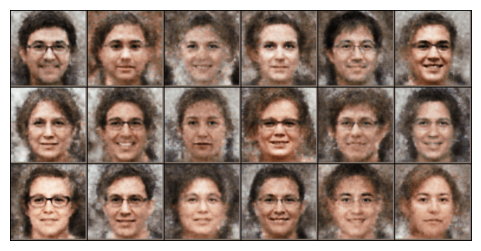

at epoch 15, loss is 7633433.8984375


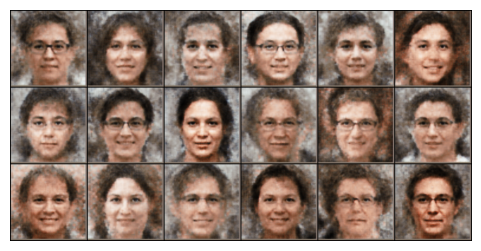

at epoch 16, loss is 7419104.5615234375


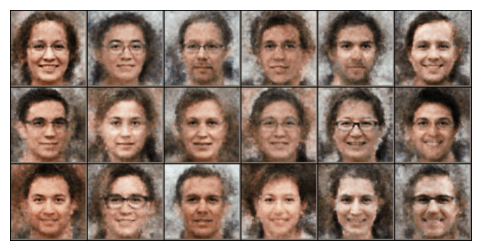

at epoch 17, loss is 7313986.501953125


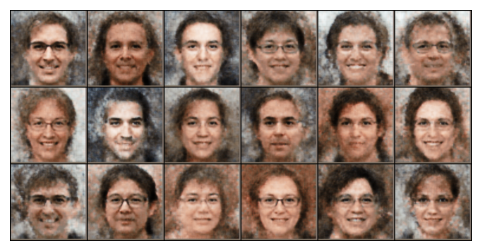

at epoch 18, loss is 7122735.0


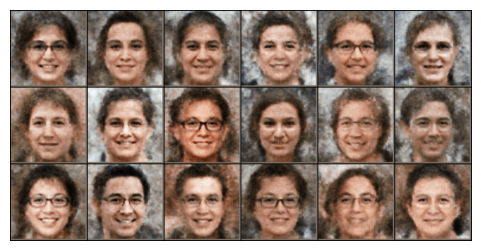

at epoch 19, loss is 7002258.63671875


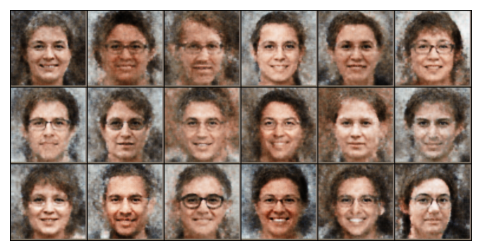

at epoch 20, loss is 6867540.0


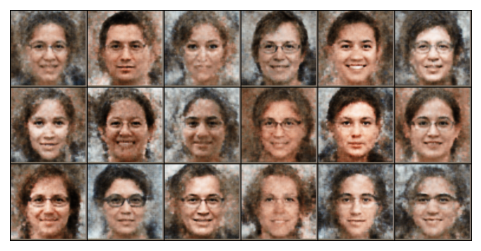

at epoch 21, loss is 6761626.6015625


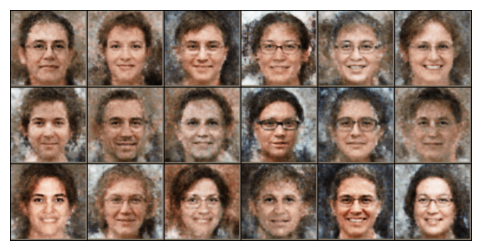

at epoch 22, loss is 6661110.431640625


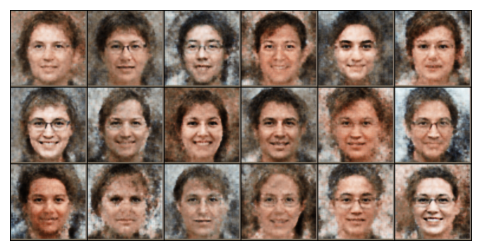

at epoch 23, loss is 6605999.1982421875


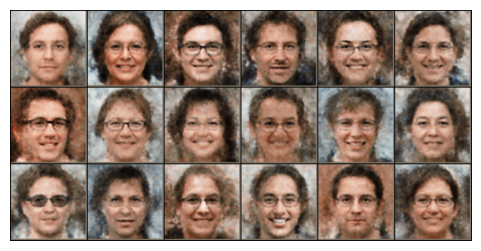

at epoch 24, loss is 6499323.869140625


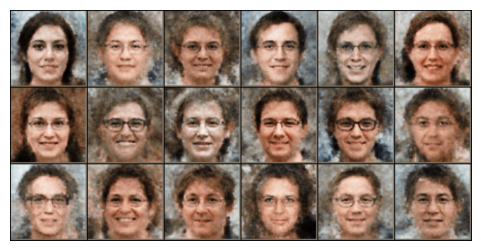

at epoch 25, loss is 6408535.4365234375


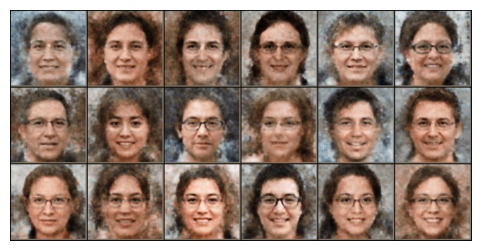

at epoch 26, loss is 6352034.103515625


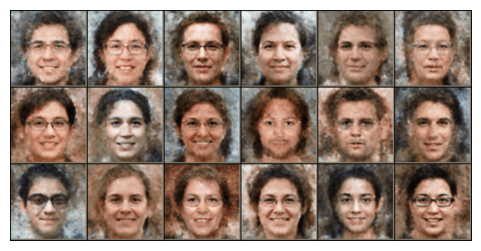

at epoch 27, loss is 6305240.4765625


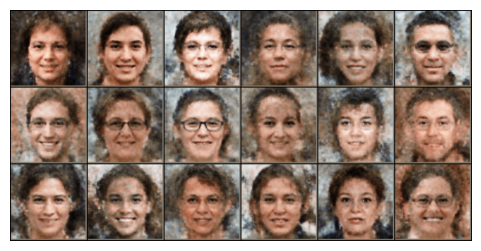

at epoch 28, loss is 6203163.9375


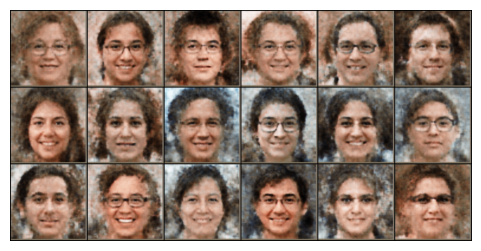

at epoch 29, loss is 6136033.349609375


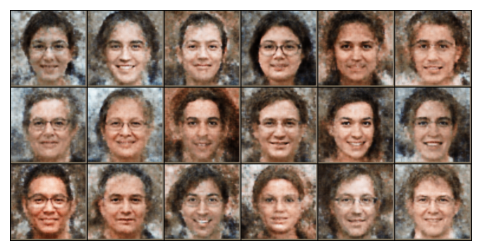

at epoch 30, loss is 6136364.2080078125


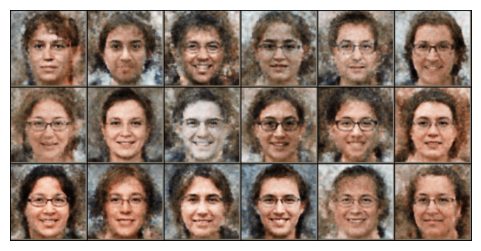

at epoch 31, loss is 5993063.1240234375


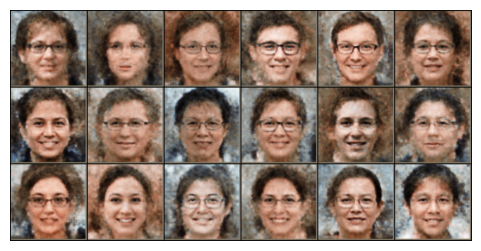

at epoch 32, loss is 5987937.95703125


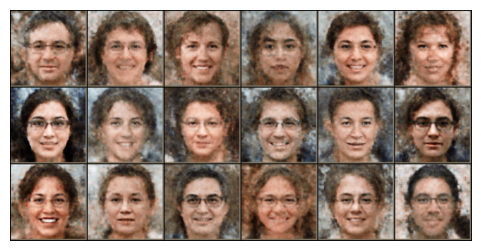

at epoch 33, loss is 5949756.2060546875


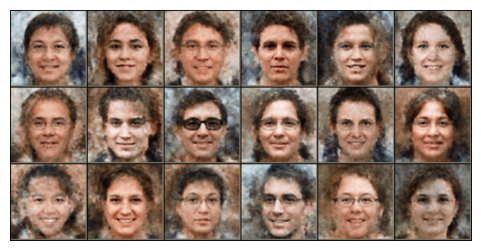

at epoch 34, loss is 5864532.728515625


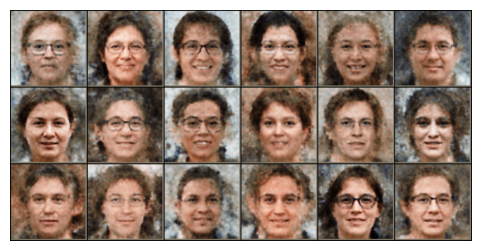

at epoch 35, loss is 5834996.970703125


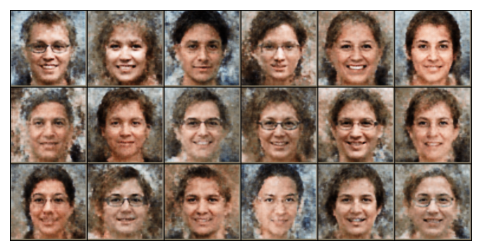

at epoch 36, loss is 5831072.865234375


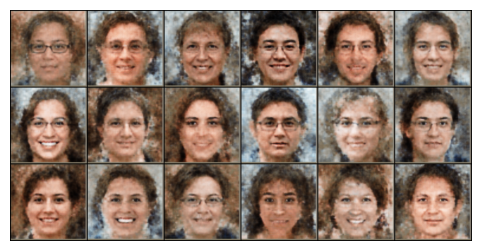

at epoch 37, loss is 5733470.882324219


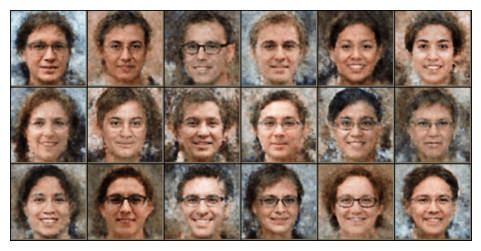

at epoch 38, loss is 5703036.0625


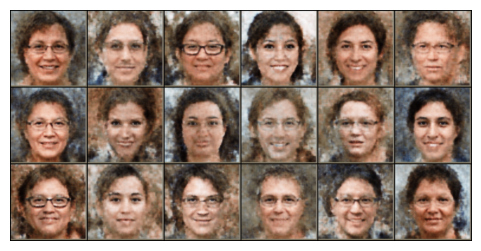

at epoch 39, loss is 5621794.7255859375


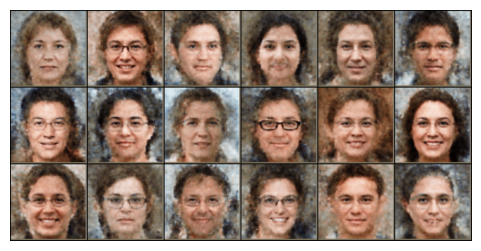

at epoch 40, loss is 5592046.2587890625


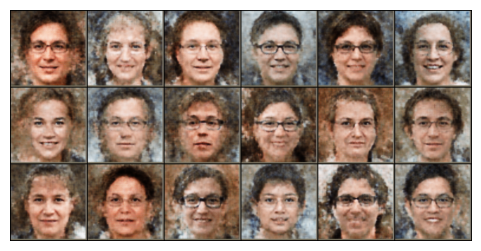

at epoch 41, loss is 5571170.09375


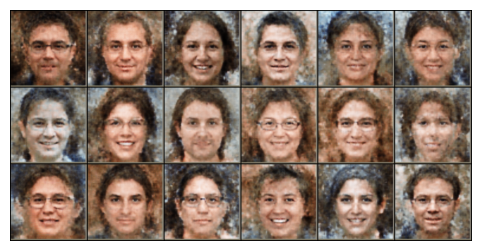

at epoch 42, loss is 5572150.076171875


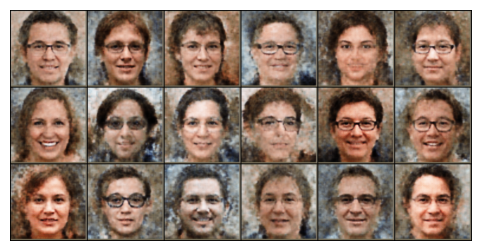

at epoch 43, loss is 5542864.8408203125


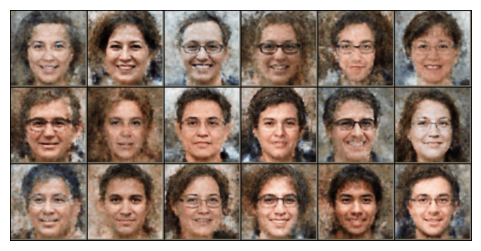

at epoch 44, loss is 5444973.2880859375


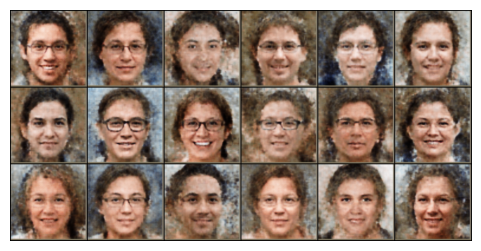

at epoch 45, loss is 5445450.3798828125


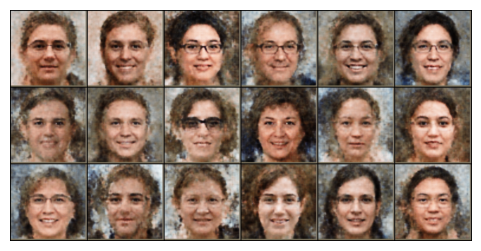

at epoch 46, loss is 5450484.3017578125


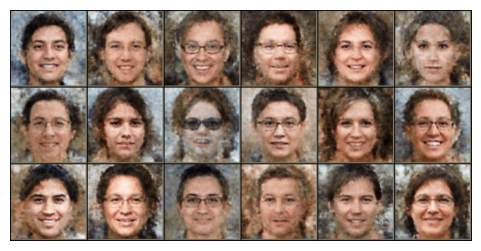

at epoch 47, loss is 5419293.505859375


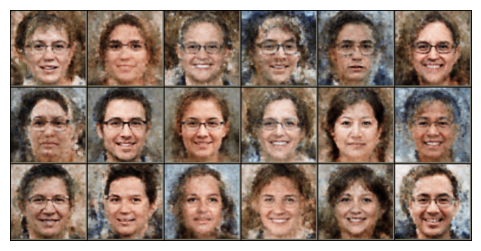

at epoch 48, loss is 5344292.26953125


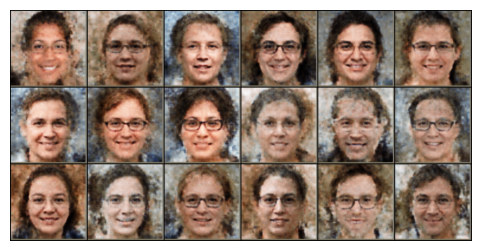

at epoch 49, loss is 5323798.8046875


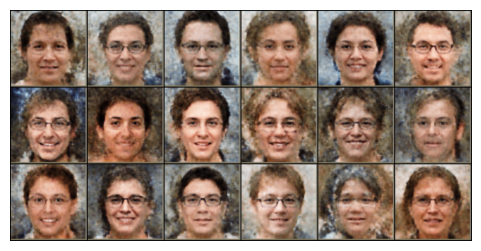

at epoch 50, loss is 5308565.756347656


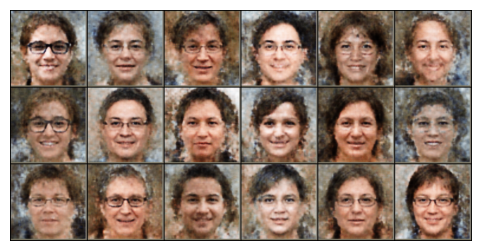

at epoch 51, loss is 5286499.925292969


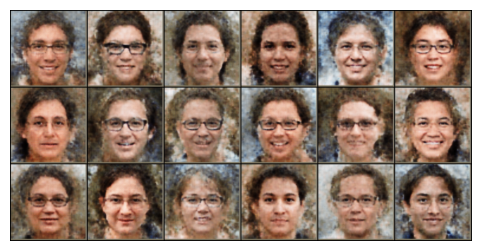

at epoch 52, loss is 5224918.1484375


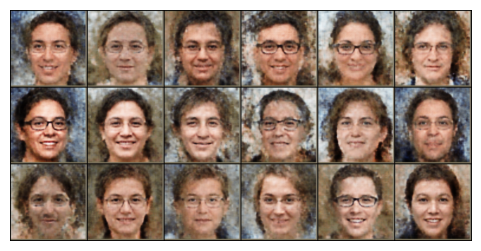

at epoch 53, loss is 5242817.7685546875


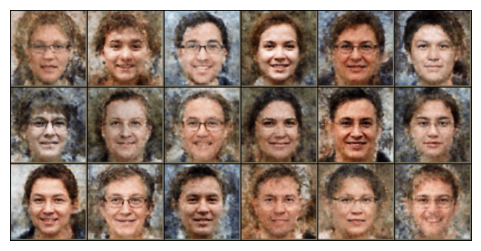

at epoch 54, loss is 5192249.83984375


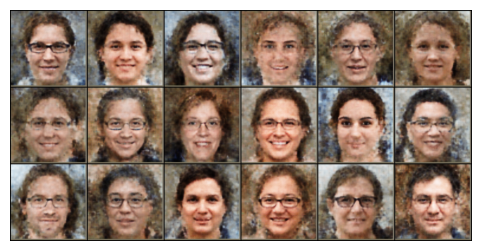

at epoch 55, loss is 5199157.9990234375


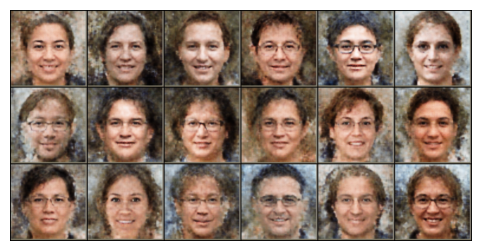

at epoch 56, loss is 5198961.7919921875


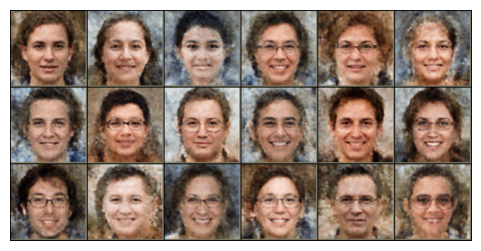

at epoch 57, loss is 5149263.537109375


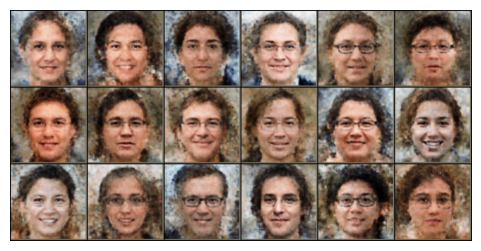

at epoch 58, loss is 5133774.4658203125


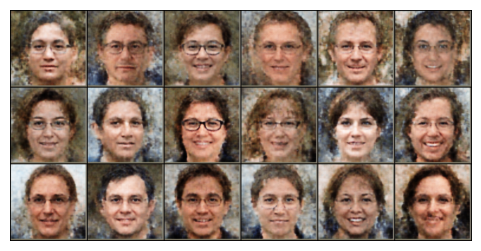

at epoch 59, loss is 5102067.3662109375


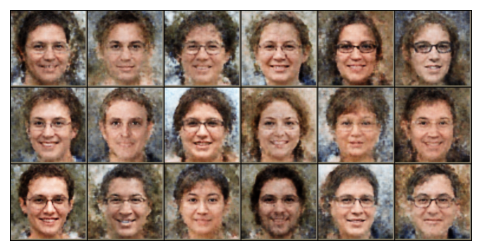

at epoch 60, loss is 5061749.3447265625


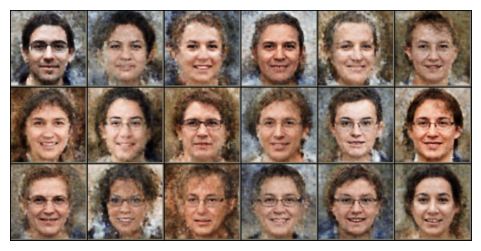

at epoch 61, loss is 5086494.865234375


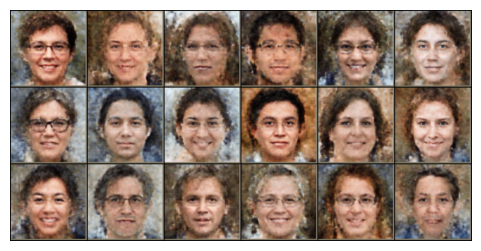

at epoch 62, loss is 5068336.15234375


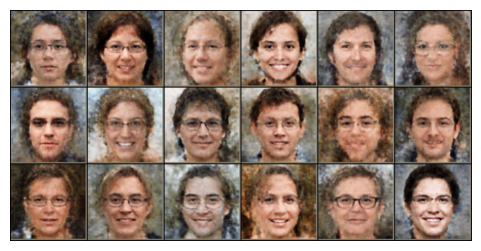

at epoch 63, loss is 5023722.3310546875


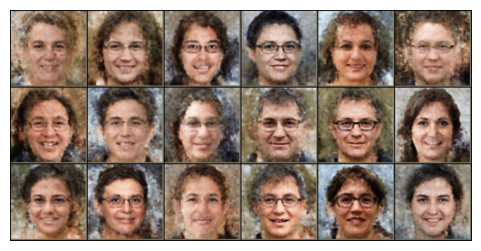

at epoch 64, loss is 5007868.9599609375


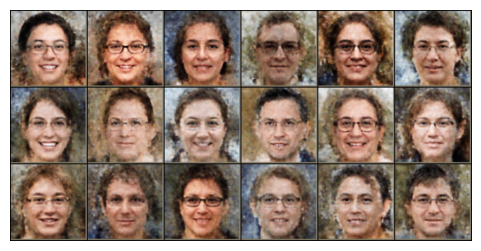

at epoch 65, loss is 5018192.646484375


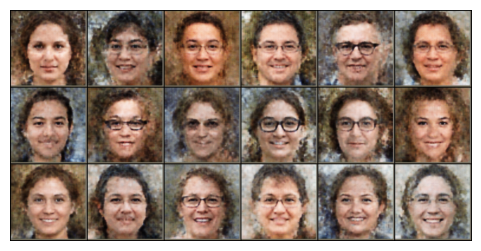

at epoch 66, loss is 4956645.723144531


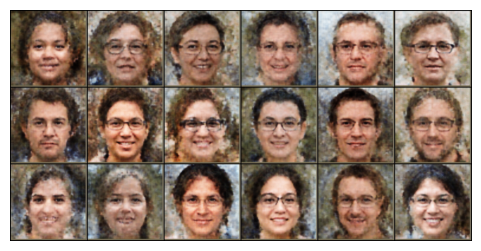

at epoch 67, loss is 4946920.542480469


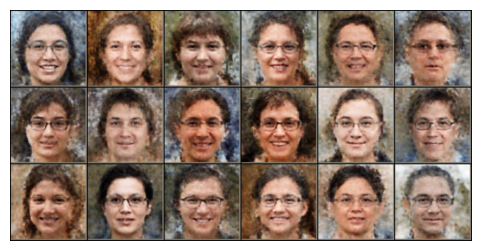

at epoch 68, loss is 4945035.802734375


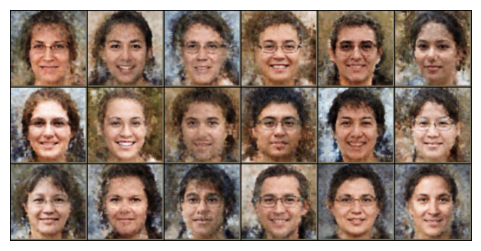

at epoch 69, loss is 4910838.0302734375


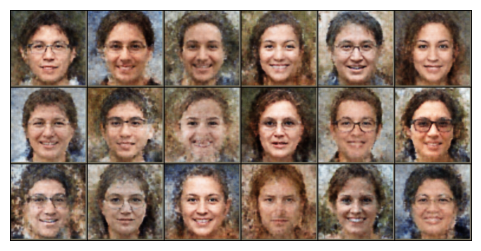

at epoch 70, loss is 4855401.229980469


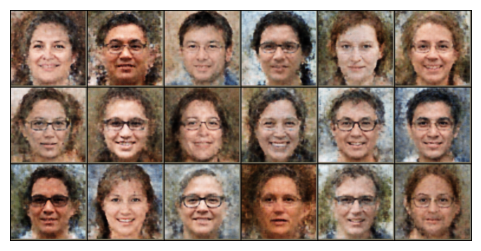

at epoch 71, loss is 4906894.4501953125


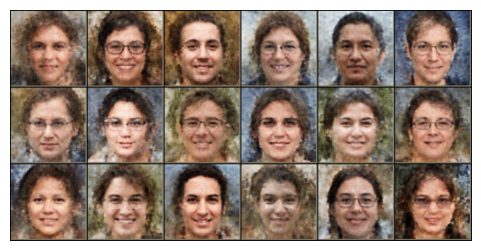

at epoch 72, loss is 4900348.7236328125


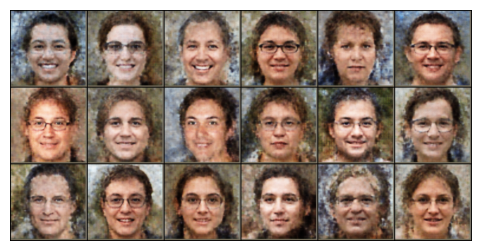

at epoch 73, loss is 4844349.9765625


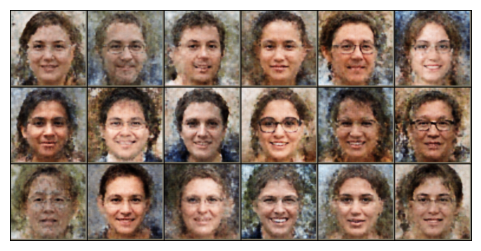

at epoch 74, loss is 4835189.2734375


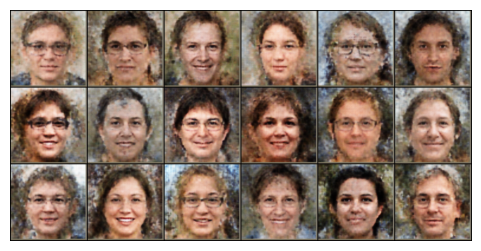

at epoch 75, loss is 4819739.0810546875


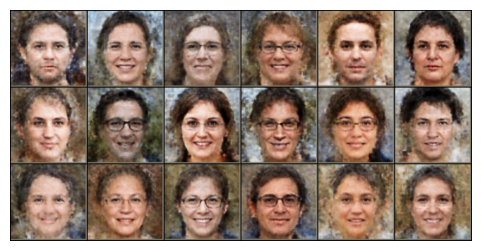

In [15]:
vae = VAE().to(device)
lr = 1e-4
optimizer = torch.optim.Adam(vae.parameters(), lr = lr, weight_decay = 1e-5)
for epoch in range(75):
    train_epoch(epoch)
    plot_epoch()
torch.save(vae.state_dict(), 'model/VAEglasses.pth')

### 潜空间属性编辑：给一张脸加 / 摘眼镜

在潜空间里找一个"眼镜方向"

$$\Delta = \mathbb{E}[\mu \mid \text{戴眼镜}] - \mathbb{E}[\mu \mid \text{不戴眼镜}]$$

然后让一张脸的编码沿 $\pm\Delta$ 走（负 → 不戴，正 → 戴）。

四个要点：

- **用 $\mu$ 不用 $z$**：$\mu$ 是确定性编码，稳定、可复现；$z=\mu+\sigma\varepsilon$ 每次带随机噪声。
- 预处理必须和训练一致：`Resize(256) + ToTensor`，**不要加 Normalize**。
- 推理必须 `vae.eval()`：解码器里有 BatchNorm。
- 加一条**随机方向对照**：它不该有语义变化 —— 用来证明 $\Delta$ 真的在控制"戴眼镜"。

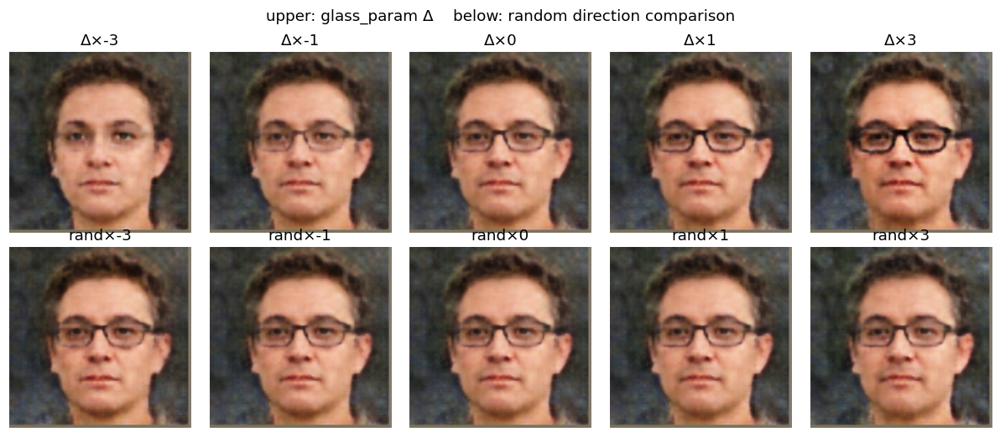

已保存 test/edit_result.jpg　上排 = 眼镜方向，下排 = 随机对照


In [19]:
# ==================== 潜空间属性编辑：给一张脸加 / 摘眼镜 ====================
# 自包含：重新载入训练好的 VAE，这一格可以单独运行
vae = VAE().to(device)
vae.load_state_dict(torch.load('model/VAEglasses.pth', map_location=device))
vae.eval()                                    # 推理必须 eval（解码器里有 BatchNorm）

IMG_SIZE = 256                                # 必须与训练一致（模型里硬编码了 31*31*32）
prep = T.Compose([T.Resize(IMG_SIZE), T.CenterCrop(IMG_SIZE), T.ToTensor()])   # 不要加 Normalize

def load_img(p):
    # 单张图 -> [1, 3, H, W]（补 batch 维）
    return prep(Image.open(p).convert('RGB')).unsqueeze(0).to(device)

# ---- 1) 用 μ 估计"眼镜方向"： Δ = mean(μ|戴眼镜) - mean(μ|不戴眼镜) ----重新运行是因为一开始的训练过程没有得出delta这个方向向量
gi, ng = data.class_to_idx['glasses'], data.class_to_idx['no_glasses']
mu_sum = {gi: torch.zeros(latent_dims, device=device), ng: torch.zeros(latent_dims, device=device)}
cnt = {gi: 0, ng: 0}
with torch.no_grad():
    for imgs, labels in dataloader:
        mu, _, _ = vae.encoder(imgs.to(device))       # 取 μ（第 1 个返回值），不用采样 z
        for c in (gi, ng):
            m = labels == c    #m的作用是找到一个batch里面对应类别的行（为True的行），相当于提供了一个索引
            mu_sum[c] += mu[m].sum(dim=0)    #本批次里属于类 c 的所有图的编码加起来
            cnt[c] += int(m.sum())    #bool数的好处，可以直接求和
mu_cls = {c: mu_sum[c] / cnt[c] for c in (gi, ng)}
delta = mu_cls[gi] - mu_cls[ng]
delta = delta / delta.norm()                      # 归一化：步长以"类均值间距"为单位，这里的delta有点像单位方向向量

# ---- 2) 沿 Δ 遍历一张测试脸；再加一条随机方向作为对照 ----
img = load_img('test/input.jpg')
alphas = [-3.0, -1.0, 0.0, 1.0, 3.0]              # 负 → 不戴眼镜，正 → 戴眼镜
torch.manual_seed(0)
delta_rand = torch.randn_like(delta); delta_rand = delta_rand / delta_rand.norm()

with torch.no_grad():
    mu0, _, _ = vae.encoder(img)
    strip_real = torch.cat([vae.decoder(mu0 + a * delta)      for a in alphas], dim=0)   # [5,3,H,W]
    strip_rand = torch.cat([vae.decoder(mu0 + a * delta_rand) for a in alphas], dim=0)

# ---- 3) 可视化 + 保存 ----
fig, axes = plt.subplots(2, len(alphas), figsize=(2.2 * len(alphas), 4.8), dpi=110)
for j, a in enumerate(alphas):
    axes[0, j].imshow(strip_real[j].detach().cpu().permute(1, 2, 0)); axes[0, j].set_title(f'Δ×{a:.0f}');   axes[0, j].axis('off')
    axes[1, j].imshow(strip_rand[j].detach().cpu().permute(1, 2, 0)); axes[1, j].set_title(f'rand×{a:.0f}'); axes[1, j].axis('off')
fig.suptitle('upper: glass_param Δ    below: random direction comparison')
plt.tight_layout(); plt.show()

save_image(torch.cat([strip_real, strip_rand], dim=0), 'test/edit_result.jpg', nrow=len(alphas))
print('已保存 test/edit_result.jpg　上排 = 眼镜方向，下排 = 随机对照')

# （可选）书里的"三连算术"版本：需要两张"同一人、戴/不戴"的图才干净
# mu_w, _, _ = vae.encoder(load_img('test/man_glasses.jpg'))
# mu_n, _, _ = vae.encoder(load_img('test/man_no_glasses.jpg'))
# out = vae.decoder(mu0 - mu_w + mu_n)